# PMOS ON / OFF — Data preprocessing

1. Load the data (20,000 samples per case)
2. Check the input columns
3. Check the output columns + data-quality checks
4. Input feature plots
5. Physics feature engineering
6. Split 80 / 10 / 10 with seed `12175305` + split check
7. Normalization of inputs (and of the log targets, for the MLP) + Plot 4
8. Feature engineering for polynomial regression (done later, at the model stage)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED  = 12175305          # same seed as the Data_Generation scripts
CASES = ["PMOS_ON", "PMOS_OFF"]

# Repo root = first parent folder that contains Data_Generation/
ROOT = Path.cwd().resolve()
while not (ROOT / "Data_Generation").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook from inside the DVD-Project repo")
    ROOT = ROOT.parent
DATA_DIR = ROOT / "Data_Generation" / "Datasets"

pd.set_option("display.float_format", lambda v: f"{v:.4g}")

# Chart style
BLUE, LIGHT_BLUE = "#2a78d6", "#9ec5f4"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 10, "font.size": 9,
})

## 1. Load the data

**20,000 samples per case** (`PMOS_ON_20k.csv`, `PMOS_OFF_20k.csv`):

| Rows | Content |
|---|---|
| 0 – 9,999 | the original dataset (team seed `12175305`) |
| 10,000 – 19,999 | 10,000 **additional** samples: the **same seed**, continuing the random sequence after the first 10,000 draws (`generate_pmos_20k.py`), so no sample repeats |

**Why more data:** the spec allows it ("the number of samples may be increased or decreased as needed"). A learning curve
on the original PMOS_OFF data (MLP, validation error, average of 3 seeds) showed the error still falling with more
training rows, so more data was expected to improve accuracy, especially the mean error:

| Training rows | median err | 95th pct err | mean err |
|---|---|---|---|
| 1,750 | 2.51 % | 18.5 % | 11.2 % |
| 3,500 | 1.87 % | 11.2 % | 7.67 % |
| 5,250 | 0.96 % | 6.12 % | 5.08 % |
| 7,000 | 1.39 % | 7.49 % | 5.04 % |

In [2]:
raw = {case: pd.read_csv(DATA_DIR / f"{case}_20k.csv") for case in CASES}
for case, df in raw.items():
    print(f"{case}: {df.shape[0]} rows x {df.shape[1]} columns   missing values: {df.isna().sum().sum()}")
raw["PMOS_ON"].head()

PMOS_ON: 20000 rows x 16 columns   missing values: 0
PMOS_OFF: 20000 rows x 16 columns   missing values: 0


,vdd,temp,w,vd,vs,vg,vb,vth0,toxe,ndep,u0,xj,id,ig,is,ib
0,0.9477,51.96,3.558e-07,0.741,0.9303,0,0.9477,-0.2275,8.7e-10,2.836e+18,0.004049,1.484e-08,9.735e-05,1.496e-07,-9.749e-05,-4.276e-09
1,0.9112,78.16,2.154e-07,0.6295,0.05801,0,0.9112,-0.2177,8.603e-10,2.856e+18,0.00422,1.308e-08,-7.725e-05,2.516e-08,7.723e-05,-9.959e-11
2,0.9365,37.83,3.271e-07,0.5743,0.1174,0,0.9365,-0.2454,9.123e-10,2.863e+18,0.003782,1.528e-08,-7.585e-05,1.192e-08,7.584e-05,-6.514e-12
3,0.974,-7.93,7.593e-08,0.353,0.5113,0,0.974,-0.2372,8.808e-10,2.602e+18,0.00421,1.405e-08,8.843e-06,2.919e-09,-8.846e-06,-1.173e-13
4,0.9206,40.03,1.447e-07,0.1416,0.6122,0,0.9206,-0.2118,9.072e-10,2.636e+18,0.004207,1.496e-08,4.78e-05,7.543e-09,-4.78e-05,-9.952e-12


## 2. Input columns

| Column | Meaning | Range |
|---|---|---|
| `vdd` | supply voltage | 0.81 – 0.99 V (0.9 V ± 10 %) |
| `temp` | temperature | −40 – 125 °C |
| `w` | transistor width | 45 – 360 nm (1 – 8 × Lmin) |
| `vd`, `vs` | drain and source voltage | 0 – vdd |
| `vg`, `vb` | gate and body voltage | fixed by the case: PMOS ON → vg = 0, vb = vdd · PMOS OFF → vg = vdd, vb = vdd |
| `vth0`, `toxe`, `ndep`, `u0`, `xj` | process parameters (PMOS values from `45nm_MGK.pm`) | nominal ± 10 % |

`vg` and `vb` are either constant or equal to `vdd`, so they carry no extra information and are **not used as features**.
(A constant column would also break normalization, because its standard deviation is 0.)

In [3]:
INPUT_COLS = ["vdd", "temp", "w", "vd", "vs", "vg", "vb", "vth0", "toxe", "ndep", "u0", "xj"]

for case, df in raw.items():
    for c in ["vg", "vb"]:
        if df[c].nunique() == 1:
            print(f"{case}: {c} is constant = {df[c].iloc[0]}")
        elif np.allclose(df[c], df["vdd"]):
            print(f"{case}: {c} is identical to vdd")

FEATURES = [c for c in INPUT_COLS if c not in ("vg", "vb")]
print("\nFeatures used:", FEATURES)
print("PMOS_ON and PMOS_OFF use the same random inputs:",
      np.allclose(raw["PMOS_ON"][FEATURES], raw["PMOS_OFF"][FEATURES]))
raw["PMOS_ON"][INPUT_COLS].describe().T

PMOS_ON: vg is constant = 0.0
PMOS_ON: vb is identical to vdd
PMOS_OFF: vg is identical to vdd
PMOS_OFF: vb is identical to vdd

Features used: ['vdd', 'temp', 'w', 'vd', 'vs', 'vth0', 'toxe', 'ndep', 'u0', 'xj']
PMOS_ON and PMOS_OFF use the same random inputs: True


,count,mean,std,min,25%,50%,75%,max
vdd,2e+04,0.9002,0.05183,0.81,0.8556,0.9,0.9451,0.99
temp,2e+04,42.31,47.51,-40,1.407,41.82,83.36,125
w,2e+04,2.017e-07,9.118e-08,4.501e-08,1.227e-07,2.011e-07,2.806e-07,3.6e-07
vd,2e+04,0.4466,0.2622,2.252e-07,0.2177,0.4432,0.6683,0.9835
vs,2e+04,0.4514,0.262,7.931e-05,0.2239,0.4511,0.6741,0.9862
vg,2e+04,0,0,0,0,0,0,0
vb,2e+04,0.9002,0.05183,0.81,0.8556,0.9,0.9451,0.99
vth0,2e+04,-0.2311,0.01333,-0.2543,-0.2427,-0.2311,-0.2196,-0.2081
toxe,2e+04,9.21e-10,5.317e-11,8.28e-10,8.752e-10,9.214e-10,9.671e-10,1.012e-09
ndep,2e+04,2.802e+18,1.615e+17,2.52e+18,2.663e+18,2.802e+18,2.942e+18,3.08e+18


## 3. Output columns

| Column | Meaning |
|---|---|
| `id` | drain current (A) |
| `ig` | gate current (A) |
| `is` | source current (A) |
| `ib` | body current (A) |

The sign gives the direction of the current. The currents span many decades, so the models will learn
**log10|I|**, and the **sign** is kept separately (only `id` and `is` change sign).

In [4]:
OUTPUT_COLS = ["id", "ig", "is", "ib"]

rows = []
for case, df in raw.items():
    for c in OUTPUT_COLS:
        a = df[c].abs()
        rows.append({"case": case, "current": c, "min |I| (A)": a.min(), "max |I| (A)": a.max(),
                     "decades": np.log10(a.max() / a.min()),
                     "% negative": 100 * (df[c] < 0).mean(), "zeros": int((df[c] == 0).sum())})
pd.DataFrame(rows).set_index(["case", "current"])

min |I| (A)  max |I| (A)  decades  % negative  zeros
case     current                                                      
PMOS_ON  id         1.642e-12    0.0002761    8.226       49.25      0
         ig          1.44e-12    2.465e-07    5.234           0      0
         is         9.376e-13    0.0002761    8.469       50.78      0
         ib         1.005e-14    2.109e-08    6.322         100      0
PMOS_OFF id         4.747e-14      4.9e-07    7.014       14.96      0
         ig         5.151e-13    8.699e-08    5.228         100      0
         is         2.468e-13    4.463e-07    6.257       15.34      0
         ib         1.769e-16    6.814e-14    2.586         100      0

In [5]:
# Targets: magnitude as log10|I| and direction as sign, kept separately
Y_log = {case: np.log10(df[OUTPUT_COLS].abs()) for case, df in raw.items()}
SIGN  = {case: np.sign(df[OUTPUT_COLS]).astype(int) for case, df in raw.items()}
Y_log["PMOS_ON"].describe().T

,count,mean,std,min,25%,50%,75%,max
id,2e+04,-4.78,0.9435,-11.78,-5.06,-4.522,-4.161,-3.559
ig,2e+04,-8.328,0.8911,-11.84,-8.734,-8.157,-7.71,-6.608
is,2e+04,-4.78,0.9432,-12.03,-5.06,-4.523,-4.161,-3.559
ib,2e+04,-11.23,1.484,-14,-12.43,-11.12,-10.04,-7.676


### Data-quality checks

- **Duplicates** and **non-finite** log targets (a current of exactly 0 would give log = −∞).
- **Kirchhoff:** `id + ig + is + ib` should be ≈ 0 for every row (shown relative to the largest current in that row).
- **No outlier removal:** every row is a valid SPICE result. Extreme values (e.g. very small `ib`) are real physics,
  and removing them would bias the models.

In [6]:
for case, df in raw.items():
    duplicates = int(df.duplicated().sum())
    non_finite = int((~np.isfinite(Y_log[case])).sum().sum())
    kcl = df[OUTPUT_COLS].sum(axis=1).abs() / df[OUTPUT_COLS].abs().max(axis=1)
    print(f"{case}: duplicate rows {duplicates} | non-finite log targets {non_finite} | "
          f"Kirchhoff residual / largest current: median {kcl.median():.1e}, max {kcl.max():.1e}")

PMOS_ON: duplicate rows 0 | non-finite log targets 0 | Kirchhoff residual / largest current: median 8.1e-07, max 9.1e-06
PMOS_OFF: duplicate rows 0 | non-finite log targets 0 | Kirchhoff residual / largest current: median 9.8e-07, max 2.2e-04


## 4. Input feature plots

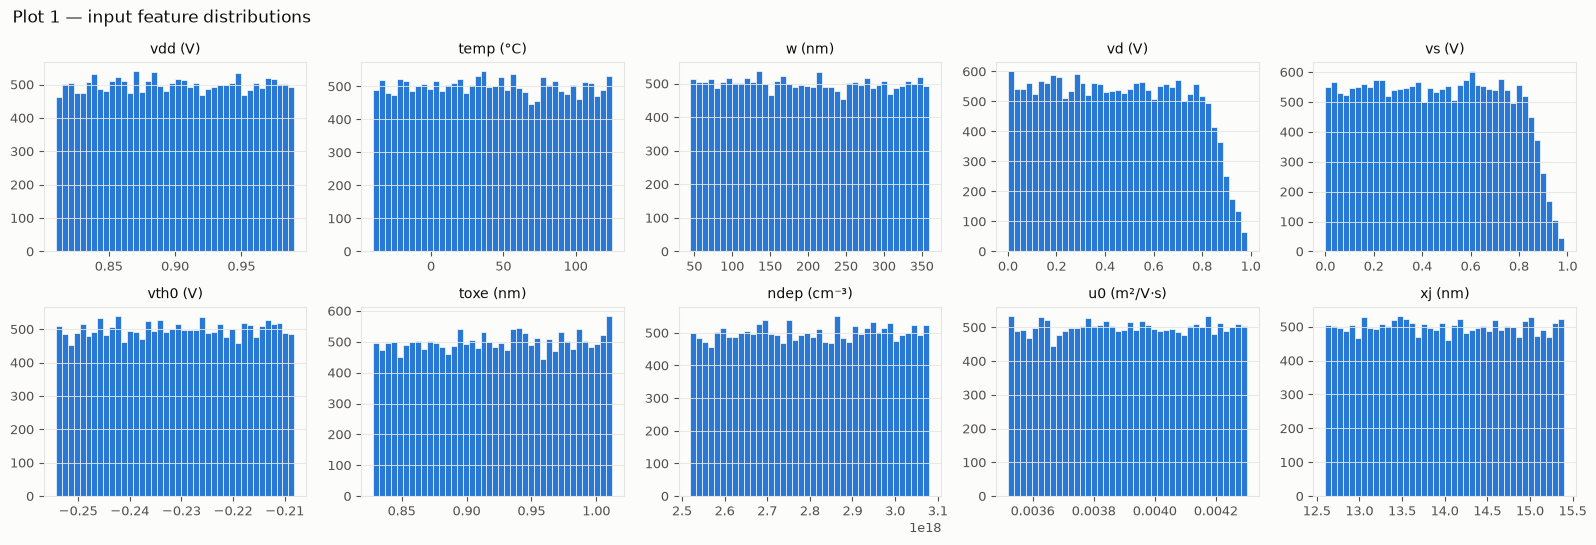

In [7]:
# Plot 1 — distribution of each input feature (PMOS_ON; PMOS_OFF has the same inputs)
UNITS = {"vdd": "V", "temp": "°C", "w": "nm", "vd": "V", "vs": "V",
         "vth0": "V", "toxe": "nm", "ndep": "cm⁻³", "u0": "m²/V·s", "xj": "nm"}
SCALE = {"w": 1e9, "toxe": 1e9, "xj": 1e9}           # show lengths in nm

fig, axes = plt.subplots(2, 5, figsize=(16, 5.5))
for ax, c in zip(axes.flat, FEATURES):
    ax.hist(raw["PMOS_ON"][c] * SCALE.get(c, 1), bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(f"{c} ({UNITS[c]})")
    ax.grid(axis="x", visible=False)
fig.suptitle("Plot 1 — input feature distributions", color=INK, fontsize=12, x=0.01, ha="left")
fig.tight_layout()
plt.show()

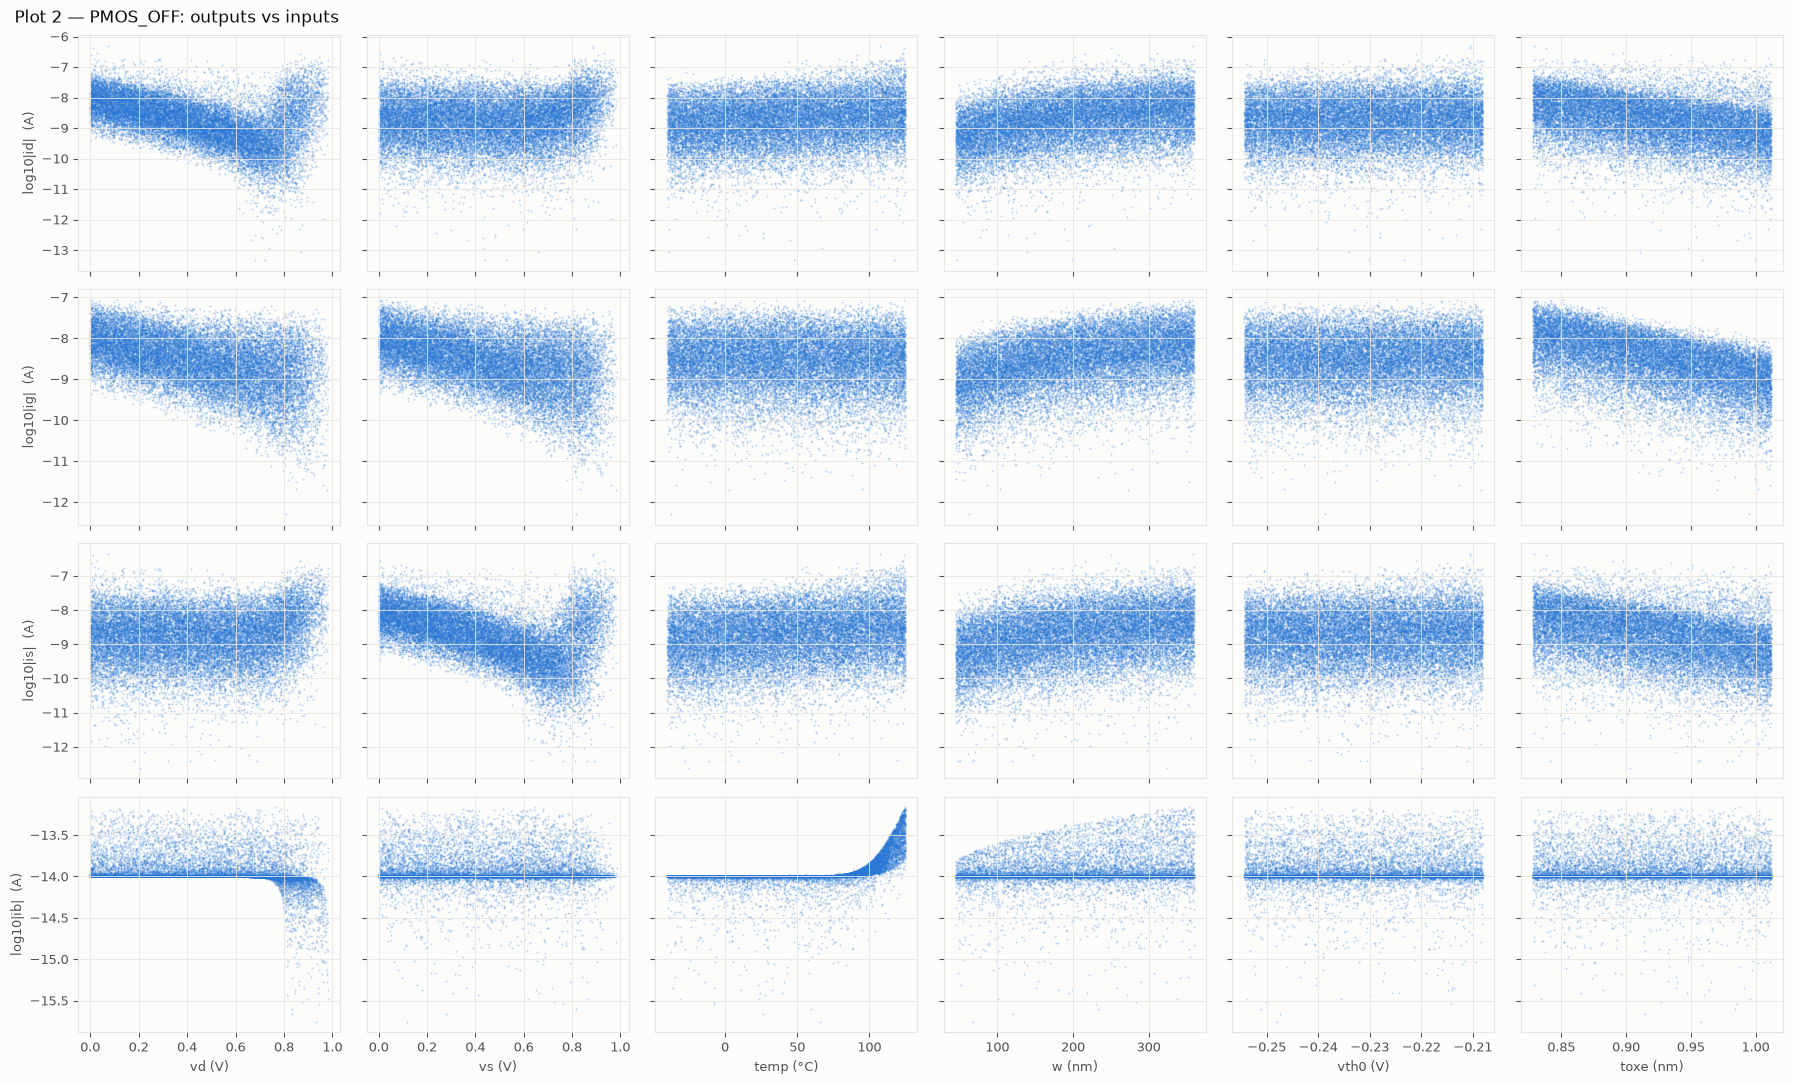

In [8]:
# Plot 2 — how each output (log10|I|) depends on the inputs
CASE = "PMOS_OFF"                     # change to "PMOS_ON" to see the other case
x_cols = ["vd", "vs", "temp", "w", "vth0", "toxe"]

fig, axes = plt.subplots(4, 6, figsize=(18, 11), sharex="col", sharey="row")
for i, out in enumerate(OUTPUT_COLS):
    for j, c in enumerate(x_cols):
        ax = axes[i, j]
        ax.scatter(raw[CASE][c] * SCALE.get(c, 1), Y_log[CASE][out],
                   s=2, alpha=0.3, color=BLUE, linewidths=0, rasterized=True)
        if i == len(OUTPUT_COLS) - 1:
            ax.set_xlabel(f"{c} ({UNITS[c]})")
        if j == 0:
            ax.set_ylabel(f"log10|{out}|  (A)")
fig.suptitle(f"Plot 2 — {CASE}: outputs vs inputs", color=INK, fontsize=12, x=0.01, ha="left")
fig.tight_layout()
plt.show()

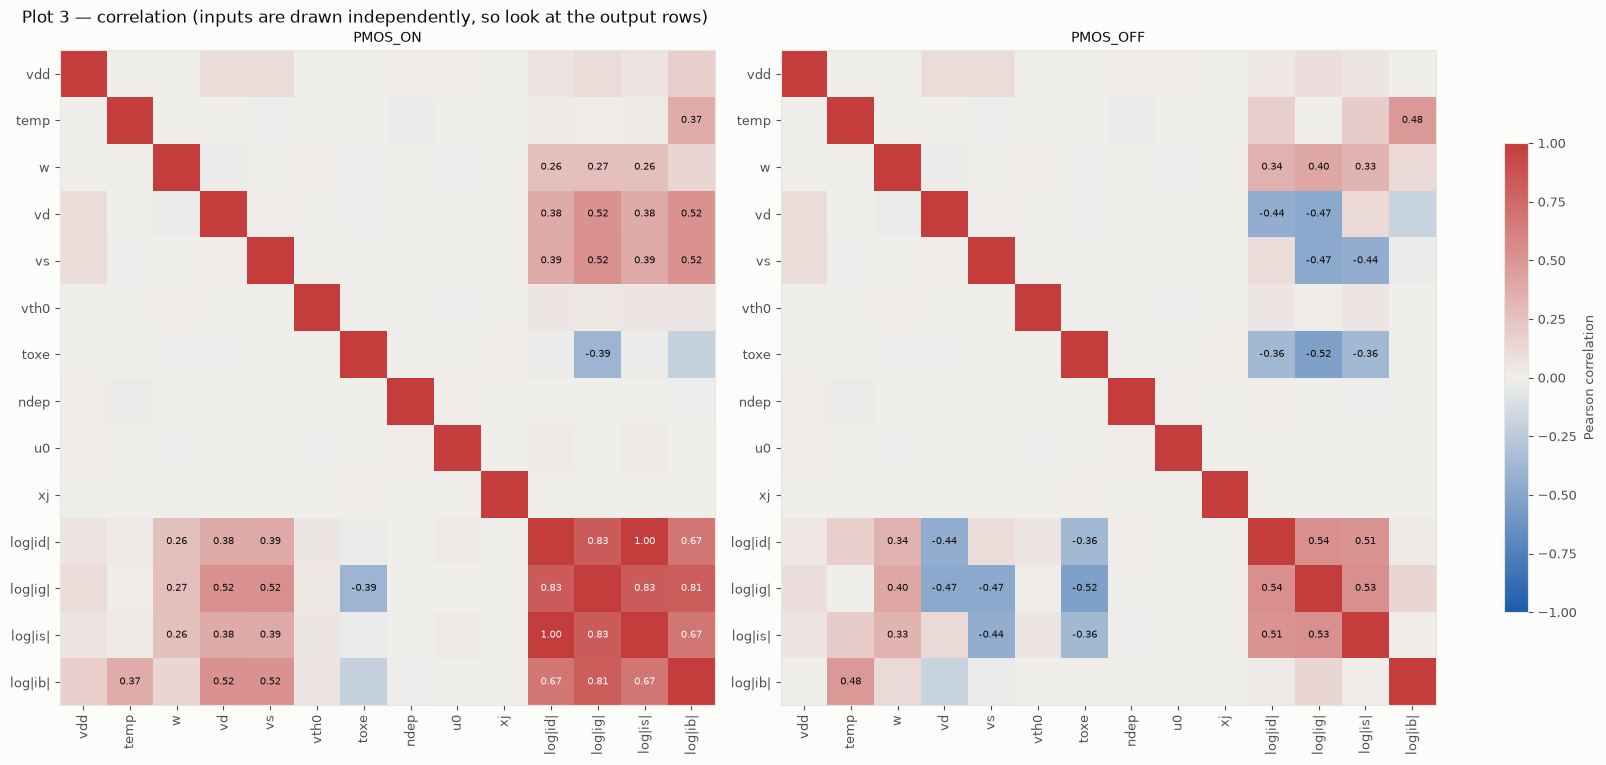

In [9]:
# Plot 3 — correlation matrix of the inputs and log10|outputs|
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#1c5cab", "#f0efec", "#c43d3c"])

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), layout="constrained")
for ax, case in zip(axes, CASES):
    table = pd.concat([raw[case][FEATURES], Y_log[case].add_prefix("log|").add_suffix("|")], axis=1)
    corr = table.corr()
    im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.columns)
    ax.grid(False)
    for r in range(len(corr)):
        for c in range(len(corr)):
            v = corr.iat[r, c]
            if r != c and abs(v) >= 0.2:              # label only the notable correlations
                ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
                        color=SURFACE if abs(v) > 0.6 else INK)
    ax.set_title(case)
fig.colorbar(im, ax=axes, shrink=0.7, label="Pearson correlation")
fig.suptitle("Plot 3 — correlation (inputs are drawn independently, so look at the output rows)",
             color=INK, fontsize=12, x=0.01, ha="left")
plt.show()

## 5. Physics feature engineering

Done **once**, before the split, and used by **all** models. The sub-threshold current

$$I \approx I_0 \frac{W}{L}\, e^{\frac{V_{gs}-V_{th}}{n V_t}} \left(1 - e^{-V_{ds}/V_t}\right), \qquad V_t = kT/q$$

becomes almost **linear** in log space when the right combinations are given as features:

| Group | Features | Why |
|---|---|---|
| Terminal differences | `vgs`, `vgd`, `vds`, `vbs`, `vbd` | currents depend on voltage *differences* |
| Effective source | `vgs_eff`, `vbs_eff`, `vds_abs` | for a PMOS the higher of vd / vs acts as the source |
| Sub-threshold physics | `overdrive_vt` = (vgs_eff − \|vth0\|) / Vt, `log_1mexp_vds` = log(1 − e^(−\|vds\|/Vt)), `inv_T`, `log_w` | exponents of the equation above |
| Gate tunnelling | `inv_toxe`, `vgs_toxe`, `vgd_toxe` | tunnelling depends on the oxide field ≈ V / toxe |

Some of these are linear combinations of the raw inputs (e.g. `vds = vd − vs`). That redundancy is harmless:
it helps the tree models, and Ridge / the MLP handle it.

In [10]:
K_B, Q_E = 1.380649e-23, 1.602176634e-19

def make_features(df, kind="pmos"):
    # raw inputs + physics features. kind = "pmos" or "nmos" (same function works for NMOS)
    f = df[FEATURES].copy()
    T  = df["temp"] + 273.15                    # Kelvin
    vt = K_B * T / Q_E                          # thermal voltage kT/q
    # terminal voltage differences
    f["vgs"] = df["vg"] - df["vs"]
    f["vgd"] = df["vg"] - df["vd"]
    f["vds"] = df["vd"] - df["vs"]
    f["vbs"] = df["vb"] - df["vs"]
    f["vbd"] = df["vb"] - df["vd"]
    # effective source: PMOS -> higher of vd / vs, NMOS -> lower of vd / vs
    if kind == "pmos":
        v_src = np.maximum(df["vd"], df["vs"])
        f["vgs_eff"] = v_src - df["vg"]         # source-to-gate drive (|Vgs| of the device)
    else:
        v_src = np.minimum(df["vd"], df["vs"])
        f["vgs_eff"] = df["vg"] - v_src
    f["vbs_eff"] = df["vb"] - v_src
    f["vds_abs"] = (df["vd"] - df["vs"]).abs()
    # sub-threshold physics
    f["overdrive_vt"]  = (f["vgs_eff"] - df["vth0"].abs()) / vt
    f["log_1mexp_vds"] = np.log(np.clip(-np.expm1(-f["vds_abs"] / vt), 1e-12, None))
    f["inv_T"] = 1.0 / T
    f["log_w"] = np.log(df["w"])
    # gate tunnelling ~ oxide field
    f["inv_toxe"] = 1.0 / df["toxe"]
    f["vgs_toxe"] = f["vgs"] / df["toxe"]
    f["vgd_toxe"] = f["vgd"] / df["toxe"]
    return f

X_all = {case: make_features(df, kind="pmos") for case, df in raw.items()}
ALL_FEATURES = list(X_all["PMOS_ON"].columns)
print(f"{len(FEATURES)} raw + {len(ALL_FEATURES) - len(FEATURES)} engineered = {len(ALL_FEATURES)} features")
print("non-finite values:", {case: int((~np.isfinite(X)).sum().sum()) for case, X in X_all.items()})

10 raw + 15 engineered = 25 features
non-finite values: {'PMOS_ON': 0, 'PMOS_OFF': 0}


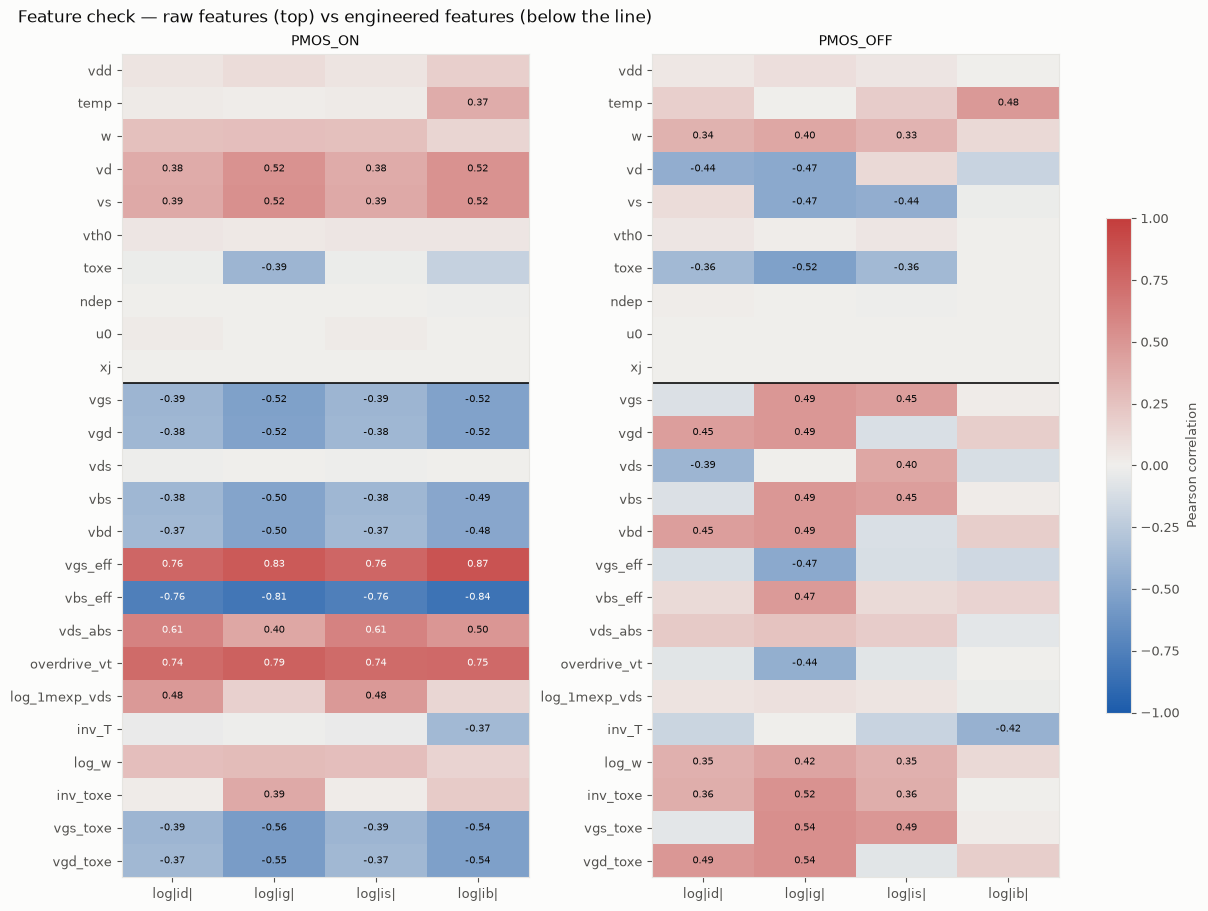

In [11]:
# Feature check — correlation of every feature with every output (do the engineered features help?)
fig, axes = plt.subplots(1, 2, figsize=(12, 9), layout="constrained")
for ax, case in zip(axes, CASES):
    corr = pd.concat([X_all[case], Y_log[case]], axis=1).corr().loc[ALL_FEATURES, OUTPUT_COLS]
    im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(OUTPUT_COLS)), [f"log|{o}|" for o in OUTPUT_COLS])
    ax.set_yticks(range(len(ALL_FEATURES)), ALL_FEATURES)
    ax.axhline(len(FEATURES) - 0.5, color=INK, lw=1.2)          # raw features above, engineered below
    ax.grid(False)
    for r in range(corr.shape[0]):
        for k in range(corr.shape[1]):
            v = corr.iat[r, k]
            if abs(v) >= 0.3:
                ax.text(k, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
                        color=SURFACE if abs(v) > 0.6 else INK)
    ax.set_title(case)
fig.colorbar(im, ax=axes, shrink=0.6, label="Pearson correlation")
fig.suptitle("Feature check — raw features (top) vs engineered features (below the line)",
             color=INK, fontsize=12, x=0.01, ha="left")
plt.show()

## 6. Split the data — 80 / 10 / 10, seed `12175305`

With 20,000 samples: **16,000 train / 2,000 validation / 2,000 test.**

- **Why 80 / 10 / 10:** the spec allows it as an alternative to 70 / 15 / 15. Training data is what improves the models
  most (see the learning curve in section 1), and with 20,000 samples the validation and test sets still have 2,000 rows
  each (more than the 1,500 of the original split), enough for stable median and 95th-percentile errors.
- The split is random over **all** 20,000 rows, so original and additional samples are mixed in every set.
- Same seed as the teammates' data-generation scripts.
- The row indices are split **once**, so every model uses exactly the same train / validation / test rows (fair comparison).
- The split is done **before** normalization, so the scalers only ever see training data.
- `X` now contains the raw **and** engineered features.

In [12]:
n = len(raw["PMOS_ON"])
assert all(len(raw[case]) == n for case in CASES)

idx = np.arange(n)
idx_train, idx_tmp = train_test_split(idx, test_size=0.20, random_state=SEED)   # 80 % train
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, random_state=SEED)  # 10 % validation, 10 % test
print(f"train {len(idx_train)}   validation {len(idx_val)}   test {len(idx_test)}")

split = {}
for case in CASES:
    X = X_all[case].values
    Y = Y_log[case].values
    S = SIGN[case].values
    split[case] = {
        "X_train": X[idx_train], "X_val": X[idx_val], "X_test": X[idx_test],
        "Y_train": Y[idx_train], "Y_val": Y[idx_val], "Y_test": Y[idx_test],
        "S_train": S[idx_train], "S_val": S[idx_val], "S_test": S[idx_test],
    }

train 16000   validation 2000   test 2000


In [13]:
# Split check — the three sets should have similar target distributions
rows = []
for case in CASES:
    for part in ["train", "val", "test"]:
        Y = split[case][f"Y_{part}"]
        rows.append({"case": case, "set": part,
                     **{f"mean log|{o}|": Y[:, k].mean() for k, o in enumerate(OUTPUT_COLS)},
                     **{f"std log|{o}|": Y[:, k].std() for k, o in enumerate(OUTPUT_COLS)}})
pd.DataFrame(rows).set_index(["case", "set"])

mean log|id|  mean log|ig|  mean log|is|  mean log|ib|  \
case     set                                                             
PMOS_ON  train         -4.78        -8.326         -4.78        -11.23   
         val          -4.785        -8.327        -4.784        -11.21   
         test          -4.78         -8.34        -4.779        -11.24   
PMOS_OFF train        -8.775        -8.578        -8.782        -13.97   
         val          -8.739        -8.577        -8.766        -13.97   
         test         -8.768        -8.578        -8.781        -13.97   

                std log|id|  std log|ig|  std log|is|  std log|ib|  
case     set                                                        
PMOS_ON  train       0.9455       0.8902        0.946        1.484  
         val         0.9447       0.9092       0.9426        1.498  
         test        0.9257       0.8792       0.9206        1.469  
PMOS_OFF train       0.7494       0.6438       0.7503        0.161  
         val         0.7581       0.6503       0.7664       0.1615  
         test        0.7559       0.6495        0.761       0.1654

## 7. Normalization (standardization)

`z = (x − mean) / std`, with mean and std taken from the **training set only** and then applied to validation and test,
so no information leaks from them into training.

**Inputs `X`**
- **Needed** for polynomial regression and the MLP: features range from about 1e-9 (`toxe`) to 1e18 (`ndep`).
- **Not needed** for random forest and XGBoost: give them the unscaled `X_*` arrays.

**Targets `Y` (log10|I|)** — standardized **for the MLP only**. The four outputs sit on different scales
(log|id| ≈ −5, log|ib| ≈ −11); scaling them gives each output equal weight in the MLP loss.
MLP predictions must be converted back with `y_scalers[case].inverse_transform(...)`.

In [14]:
scalers, y_scalers = {}, {}
for case in CASES:
    s = split[case]
    scaler = StandardScaler().fit(s["X_train"])          # inputs - fit on TRAIN only
    s["Xs_train"], s["Xs_val"], s["Xs_test"] = (scaler.transform(s[k]) for k in ("X_train", "X_val", "X_test"))
    y_scaler = StandardScaler().fit(s["Y_train"])        # log targets (MLP only) - fit on TRAIN only
    s["Ys_train"], s["Ys_val"], s["Ys_test"] = (y_scaler.transform(s[k]) for k in ("Y_train", "Y_val", "Y_test"))
    scalers[case], y_scalers[case] = scaler, y_scaler

s = split["PMOS_ON"]
pd.DataFrame({"raw min": s["X_train"].min(0), "raw max": s["X_train"].max(0),
              "scaled mean": s["Xs_train"].mean(0), "scaled std": s["Xs_train"].std(0)}, index=ALL_FEATURES)

,raw min,raw max,scaled mean,scaled std
vdd,0.81,0.99,1.31e-13,1
temp,-39.99,125,-1.975e-16,1
w,4.501e-08,3.6e-07,-1.457e-14,1
vd,2.252e-07,0.9831,3.13e-15,1
vs,7.931e-05,0.9862,8.271e-15,1
vth0,-0.2543,-0.2081,3.436e-14,1
toxe,8.28e-10,1.012e-09,2.25e-15,1
ndep,2.52e+18,3.08e+18,3.865e-15,1
u0,0.003519,0.004301,1.957e-14,1
xj,1.26e-08,1.54e-08,2.688e-15,1


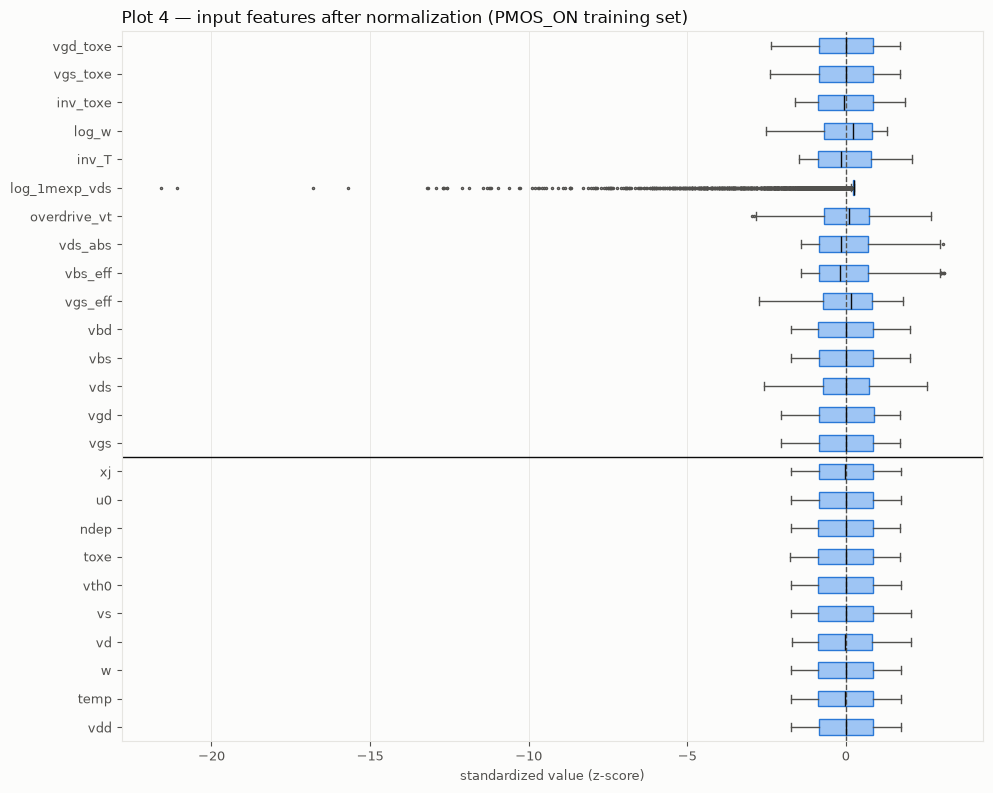

In [15]:
# Plot 4 — features after normalization (training set): all on the same scale, centred at 0
fig, ax = plt.subplots(figsize=(10, 8))
ax.boxplot(split["PMOS_ON"]["Xs_train"], orientation="horizontal", tick_labels=ALL_FEATURES, widths=0.55,
           patch_artist=True, boxprops=dict(facecolor=LIGHT_BLUE, edgecolor=BLUE),
           medianprops=dict(color=INK), whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2),
           flierprops=dict(marker=".", markersize=3, markeredgecolor=INK_2))
ax.axvline(0, color=INK_2, lw=1, ls="--")
ax.axhline(len(FEATURES) + 0.5, color=INK, lw=1)        # raw features below, engineered above
ax.set_xlabel("standardized value (z-score)")
ax.grid(axis="y", visible=False)
ax.set_title("Plot 4 — input features after normalization (PMOS_ON training set)", loc="left", fontsize=12)
plt.tight_layout()
plt.show()

## 8. Feature engineering for polynomial regression — done later, at the model stage

Polynomial features (x₁², x₁·x₂, x₁²·x₃, …) are used **only** by the polynomial model, and they must be built from the
**normalized** features. So they are created inside that model's pipeline when we train it:

```python
model = make_pipeline(PolynomialFeatures(degree=3), Ridge())
model.fit(split[case]["Xs_train"], split[case]["Y_train"])
```

## Ready for modelling

| Variable | Contents | Used by |
|---|---|---|
| `ALL_FEATURES` | names of the 10 raw + 15 engineered features | all models |
| `split[case]["X_train" / "X_val" / "X_test"]` | unscaled features | random forest, XGBoost |
| `split[case]["Xs_train" / "Xs_val" / "Xs_test"]` | normalized features | polynomial regression, MLP |
| `split[case]["Y_train" / "Y_val" / "Y_test"]` | targets log10\|I\| (`id`, `ig`, `is`, `ib`) | all models (and for scoring) |
| `split[case]["Ys_train" / "Ys_val" / "Ys_test"]` | standardized log targets | MLP training |
| `split[case]["S_train" / "S_val" / "S_test"]` | signs of the currents | sign handling |
| `scalers[case]`, `y_scalers[case]` | fitted input / target scalers | MLP, Part B |

# Modelling

## Evaluation — the same scoring for every model

All models are scored on the **validation set** (the test set is kept for the final check of the chosen model):

- **R²** on `log10|I|` (on raw currents it would only reflect the largest values)
- **% error** on the current: `|I_pred / I_true − 1| × 100 = |10^(Δlog) − 1| × 100`
- per current: the **mean**, the **median** and the **95th percentile** of that error
- the row `average` is the average of each column over the 4 currents

The **mean** is pulled up by a few very bad predictions; the **median** shows the typical sample; the
**95th percentile** shows how bad the worst 5 % get.

Every result is stored in `RESULTS[case][model name]`, which later builds the model comparison table.

In [16]:
import time
from sklearn.metrics import r2_score

RESULTS = {case: {} for case in CASES}      # RESULTS[case][model name] = {"model", "metrics", "time_s"}

def metrics_table(Y_true, Y_pred):
    # Y_true, Y_pred: log10|I| arrays with columns id, ig, is, ib
    rows = []
    for k, c in enumerate(OUTPUT_COLS):
        err = np.abs(10 ** (Y_pred[:, k] - Y_true[:, k]) - 1) * 100
        rows.append({"current": c, "R2 (log|I|)": r2_score(Y_true[:, k], Y_pred[:, k]),
                     "mean err %": err.mean(), "median err %": np.median(err),
                     "95th pct err %": np.percentile(err, 95)})
    table = pd.DataFrame(rows).set_index("current")
    table.loc["average"] = table.mean()
    return table

def record(case, name, model, Y_pred_val, seconds):
    # store a trained model and its validation scores
    m = metrics_table(split[case]["Y_val"], Y_pred_val)
    RESULTS[case][name] = {"model": model, "metrics": m, "time_s": seconds}
    a = m.loc["average"]
    print(f"{case:9s} {name:13s} validation: mean err {a['mean err %']:6.2f} %   "
          f"median err {a['median err %']:6.2f} %   95th pct {a['95th pct err %']:6.2f} %   ({seconds:.1f} s)")

## Model 1 — Random forest regression

A decision tree splits the data with yes/no questions so that the target values in each leaf are as similar as
possible; a leaf predicts the **average** of its training samples. A random forest trains many trees, each on a random
sample of rows and features, and **averages** their predictions. One forest predicts all 4 outputs at once.

| Setting | Value | Meaning |
|---|---|---|
| `n_estimators` | 300 | number of trees |
| `max_features` | 0.5 | each split looks at a random 50 % of the features |
| `min_samples_leaf` | 1 | trees grow until each leaf holds one sample |
| `random_state` | `SEED` | reproducible |

- **Inputs:** unscaled `X_*` (trees only compare thresholds, so scaling does not matter)
- **Targets:** `Y_*` = log10|I| (not the standardized `Ys_*`, which are only for the MLP)
- Predictions are averages of leaves, so the output is a fine **staircase**, not a smooth curve — expect a few
  percent error rather than ~1 %.

In [17]:
from sklearn.ensemble import RandomForestRegressor

RF_PARAMS = dict(n_estimators=300, max_features=0.5, min_samples_leaf=1, n_jobs=8, random_state=SEED)

for case in CASES:
    s = split[case]
    t0 = time.time()
    rf = RandomForestRegressor(**RF_PARAMS).fit(s["X_train"], s["Y_train"])
    record(case, "RandomForest", rf, rf.predict(s["X_val"]), time.time() - t0)

PMOS_ON   RandomForest  validation: mean err  20.32 %   median err  14.21 %   95th pct  54.42 %   (7.2 s)


PMOS_OFF  RandomForest  validation: mean err  29.17 %   median err   9.75 %   95th pct  49.83 %   (7.4 s)


In [18]:
# Random forest — validation scores per current
pd.concat({case: RESULTS[case]["RandomForest"]["metrics"] for case in CASES}, names=["case", "current"])

R2 (log|I|)  mean err %  median err %  95th pct err %
case     current                                                       
PMOS_ON  id            0.9883       17.34         11.15           46.83
         ig            0.9843       19.22         13.31           53.43
         is             0.988       17.37         11.14           46.76
         ib            0.9902       27.37         21.24           70.67
         average       0.9877       20.32         14.21           54.42
PMOS_OFF id            0.9546       48.58         11.88           55.57
         ig            0.9721       18.99         11.44           54.61
         is            0.9547       41.23            12           58.66
         ib            0.8088       7.878         3.692           30.48
         average       0.9226       29.17         9.752           49.83

## Model 2 — XGBoost (gradient-boosted trees)

A random forest trains its trees **independently** and averages them. Boosting trains trees **one after another**:
each new small tree is fit to the **remaining error** of all the trees before it, and its prediction is added with a
small weight (the learning rate). Many small corrections add up to a much finer fit than an average of leaves, so
boosting usually beats a random forest on smooth targets like `log10|I|`.

| Setting | Value | Meaning |
|---|---|---|
| `n_estimators` | 10000 | upper limit on the number of trees (early stopping picks the real number) |
| `learning_rate` | 0.05 | each tree's correction is shrunk to 5 % — many small steps |
| `max_depth` | 4 | shallow trees; on this data many small trees beat fewer deep ones (depths 4, 5, 6 and 8 were tried on the original 10,000-sample data, 4 was best) |
| `subsample` | 0.8 | each tree sees a random 80 % of the rows |
| `colsample_bytree` | 0.8 | each tree sees a random 80 % of the features |
| `early_stopping_rounds` | 200 | stop when the validation error has not improved for 200 trees, keep the best tree count |
| `tree_method` | `hist` | fast histogram-based splitting |
| `random_state` | `SEED` | reproducible |

- **Inputs:** unscaled `X_*` (trees, so scaling does not matter)
- **Targets:** `Y_*` = log10|I|; one model predicts all 4 outputs (each round adds one tree per output)
- Early stopping looks at the validation set, so the validation score is slightly optimistic. The test set stays
  untouched for the final check.

In [19]:
from xgboost import XGBRegressor

XGB_PARAMS = dict(n_estimators=10000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                  tree_method="hist", early_stopping_rounds=200, n_jobs=8, random_state=SEED)

for case in CASES:
    s = split[case]
    t0 = time.time()
    xgb = XGBRegressor(**XGB_PARAMS)
    xgb.fit(s["X_train"], s["Y_train"], eval_set=[(s["X_val"], s["Y_val"])], verbose=False)
    record(case, "XGBoost", xgb, xgb.predict(s["X_val"]), time.time() - t0)   # predict uses the best tree count
    print(f"{'':9s} trees used: {xgb.best_iteration + 1}")

PMOS_ON   XGBoost       validation: mean err   4.37 %   median err   2.86 %   95th pct  12.61 %   (86.6 s)
          trees used: 10000


PMOS_OFF  XGBoost       validation: mean err  13.43 %   median err   3.33 %   95th pct  19.42 %   (13.4 s)
          trees used: 1826


In [20]:
# XGBoost — validation scores per current
pd.concat({case: RESULTS[case]["XGBoost"]["metrics"] for case in CASES}, names=["case", "current"])

R2 (log|I|)  mean err %  median err %  95th pct err %
case     current                                                       
PMOS_ON  id            0.9983       3.922         1.857            12.5
         ig            0.9995       3.147         2.292           8.619
         is            0.9986       3.773         1.879           12.81
         ib            0.9994        6.65         5.403           16.48
         average       0.9989       4.373         2.858           12.61
PMOS_OFF id            0.9738       24.38         5.102           33.38
         ig            0.9983       4.115         3.156           10.26
         is            0.9754       24.57         4.966           31.69
         ib             0.993      0.6667        0.1067           2.348
         average       0.9851       13.43         3.332           19.42

## Model 3 — Polynomial regression (Ridge)

A linear model can only fit straight-line relations. Polynomial regression first builds **new features from products**
of the inputs (degree 2: x₁², x₁·x₂, …; degree 3 also adds x₁³, x₁²·x₂, x₁·x₂·x₃, …) and then fits a **linear** model on all of
them. Thanks to the physics features (section 5), log10|I| is already close to linear, so low-order products can fit much of what is left.

Pipeline, built on the normalized `Xs_*` as planned in section 8:

`Xs` → `PolynomialFeatures(degree)` → `StandardScaler` → `Ridge(alpha)`

| Step | Why |
|---|---|
| `PolynomialFeatures` | all products up to `degree`. With 25 features: degree 1 → 25 terms, 2 → 350, 3 → 3 275 |
| `StandardScaler` | the products have very different spreads; rescaling lets the penalty treat every term equally |
| `Ridge` | least squares + a penalty `alpha · Σ w²` that keeps the thousands of weights small, so the model does not overfit |

**Choosing degree and alpha:** every combination of degree 1, 2, 3 and alpha 1e-4, 0.01, 1, 100 is trained, and the one
with the lowest validation **median** error is kept for each case. As with XGBoost's early stopping, this uses the
validation set; the test set stays untouched for the final check.
Degree 4 is not tried: it would create 23 750 terms, more than the 16 000 training rows.

- **Inputs:** normalized `Xs_*`
- **Targets:** `Y_*` = log10|I| (not the standardized `Ys_*`)

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

DEGREES = [1, 2, 3]
ALPHAS  = [1e-4, 1e-2, 1, 100]

def poly_ridge(degree, alpha):
    # products of the normalized features up to `degree` -> rescale them -> linear model with L2 penalty
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), Ridge(alpha=alpha))

poly_grid, best_poly = [], {}
for case in CASES:
    s = split[case]
    for degree in DEGREES:
        for alpha in ALPHAS:
            t0 = time.time()
            model = poly_ridge(degree, alpha).fit(s["Xs_train"], s["Y_train"])
            seconds = time.time() - t0
            pred = model.predict(s["Xs_val"])
            a = metrics_table(s["Y_val"], pred).loc["average"]
            poly_grid.append({"case": case, "degree": degree, "alpha": alpha, "median err %": a["median err %"]})
            if case not in best_poly or a["median err %"] < best_poly[case]["median"]:
                best_poly[case] = {"median": a["median err %"], "degree": degree, "alpha": alpha,
                                   "model": model, "pred": pred, "seconds": seconds}

# validation median error % (average over the 4 currents) for every degree / alpha
pd.DataFrame(poly_grid).pivot_table(index=["case", "degree"], columns="alpha", values="median err %")

alpha            0.0001  0.01    1       100   
case     degree                                
PMOS_OFF 1        30.72   30.72   30.71      30
         2         21.1   21.05   21.21   21.95
         3        14.59    14.6   14.67   14.82
PMOS_ON  1        40.36   40.36   40.36   40.45
         2        16.37   16.35   16.33   17.11
         3        4.538   4.464   4.467   4.527

In [22]:
# keep the best degree / alpha for each case
for case in CASES:
    b = best_poly[case]
    print(f"{case}: best degree {b['degree']}, alpha {b['alpha']:g}")
    record(case, "PolyRidge", b["model"], b["pred"], b["seconds"])

# Polynomial regression — validation scores per current
pd.concat({case: RESULTS[case]["PolyRidge"]["metrics"] for case in CASES}, names=["case", "current"])

PMOS_ON: best degree 3, alpha 0.01
PMOS_ON   PolyRidge     validation: mean err   7.02 %   median err   4.46 %   95th pct  22.10 %   (2.9 s)
PMOS_OFF: best degree 3, alpha 0.0001
PMOS_OFF  PolyRidge     validation: mean err  69.96 %   median err  14.59 %   95th pct  77.30 %   (3.0 s)


R2 (log|I|)  mean err %  median err %  95th pct err %
case     current                                                       
PMOS_ON  id            0.9988        5.26         4.014           13.28
         ig            0.9898       11.57         5.254           45.63
         is            0.9991       5.094         4.035           13.12
         ib            0.9994       6.138         4.553           16.36
         average       0.9968       7.015         4.464            22.1
PMOS_OFF id            0.8662       139.6         25.59           124.8
         ig            0.9968       3.693         1.995           8.374
         is            0.8583       125.2         25.92           151.9
         ib            0.7519       11.34         4.849           24.13
         average       0.8683       69.96         14.59            77.3

## Model 4 — MLP (neural network)

### Architecture: `25 inputs → 128 → 64 → 32 → 16 or 32 → 4 outputs`

| Part | Choice | Why |
|---|---|---|
| Input layer | 25 neurons | one per feature (normalized `Xs_*`), fixed by the data |
| Hidden layers | 4 layers: 128 → 64 → 32 → 16 or 32 | funnel shape: the wide first layer builds many combinations of the features, the narrower layers compress them into the few patterns the 4 outputs need (~14 000 weights) |
| Output layer | 4 neurons, no activation | standardized log10\|id\|, \|ig\|, \|is\|, \|ib\| — a regression output must not be squashed into a range |
| Activation | **SiLU** = x · sigmoid(x) | no vanishing gradient (≈ x for positive inputs, like ReLU) **and** smooth, so the predicted current is a smooth curve (ReLU has a corner at 0, so its fit is made of straight pieces) |
| Loss | MSE on the standardized log targets | each output gets equal weight; an error in log10 is a relative (%) error in the current |

### Training

| Part | Choice | Why |
|---|---|---|
| Optimizer | **AdamW** | Adam gives every weight its own step size from its gradient history, so it trains well without much tuning. AdamW is Adam with weight decay applied correctly (in plain Adam the decay is rescaled by the adaptive step) |
| Learning rate | 0.01, **halved** when the validation loss has not improved for 50 epochs | Adam adapts the *relative* step sizes, but the overall size still matters: large steps early, small steps at the end to reach ~1 % accuracy |
| Batch size | 256 | ~63 weight updates per epoch (16,000 training rows) |
| Regularization | weight decay 1e-4 + **early stopping** (stop after 300 epochs without improvement, keep the best epoch) | no dropout: it adds noise to training and limits the precision |
| Inputs / targets | `Xs_*` / `Ys_*` | predictions are converted back with `y_scalers[case].inverse_transform` |

### Tried on a copy during development (original 10,000-sample data, 70/15/15 split; PMOS_ON, validation median error, average over the 4 currents)

| Activation | median err | Optimizer (128-128-128 net) | median err | Regularization | median err |
|---|---|---|---|---|---|
| **SiLU** | **0.38 %** | **Adam, lr 0.01** | **0.22 %** | none | 0.39 % |
| tanh | 0.56 % | Adam, lr 0.001 | 0.32 % | **weight decay 1e-4** | **0.38 %** |
| ReLU | 1.68 % | Adam, lr 0.0001 | 0.42 % | weight decay + dropout 0.1 | 3.50 % |
| sigmoid | 0.74 % (still improving at the 3000-epoch limit: small gradients, slow learning) | RMSprop | 0.45 % | | |
| | | SGD + momentum | 1.58 % | | |

The **median** error was almost the same on training and validation data (0.35 % vs 0.38 %); the learning curves
at the end of this section check overfitting in more detail. The last hidden layer (16 or 32 neurons) is decided below
by training both.

In [23]:
import copy
import torch
from torch import nn

torch.set_num_threads(4)

def build_mlp(hidden, n_in=len(ALL_FEATURES), n_out=len(OUTPUT_COLS)):
    # 25 inputs -> hidden layers, each followed by SiLU -> 4 linear outputs
    layers, width = [], n_in
    for h in hidden:
        layers += [nn.Linear(width, h), nn.SiLU()]
        width = h
    layers.append(nn.Linear(width, n_out))
    return nn.Sequential(*layers)

MLP_PARAMS = dict(lr=1e-2, weight_decay=1e-4, batch_size=256, max_epochs=3000, patience=300)

def train_mlp(case, hidden, lr, weight_decay, batch_size, max_epochs, patience):
    s = split[case]
    torch.manual_seed(SEED)
    as_tensor = lambda a: torch.tensor(a, dtype=torch.float32)
    Xt, Yt = as_tensor(s["Xs_train"]), as_tensor(s["Ys_train"])
    Xv, Yv = as_tensor(s["Xs_val"]), as_tensor(s["Ys_val"])

    net = build_mlp(hidden)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=50, min_lr=1e-6)
    loss_fn = nn.MSELoss()
    gen = torch.Generator().manual_seed(SEED)

    best, best_state, wait = float("inf"), None, 0
    history = {"train": [], "val": []}
    for epoch in range(max_epochs):
        net.train()
        batch_losses = []
        for b in torch.randperm(len(Xt), generator=gen).split(batch_size):   # shuffled mini-batches
            opt.zero_grad()
            loss = loss_fn(net(Xt[b]), Yt[b])
            loss.backward()
            opt.step()
            batch_losses.append(loss.item())
        net.eval()
        with torch.no_grad():
            val_loss = loss_fn(net(Xv), Yv).item()
        history["train"].append(np.mean(batch_losses))
        history["val"].append(val_loss)
        sched.step(val_loss)                      # halve the learning rate when validation stops improving
        if val_loss < best:                       # early stopping: remember the best epoch
            best, best_state, wait = val_loss, copy.deepcopy(net.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(best_state)
    return net, history

def mlp_predict(net, case, Xs):
    # normalized inputs -> log10|I| (undo the target standardization)
    net.eval()
    with torch.no_grad():
        Ys = net(torch.tensor(Xs, dtype=torch.float32)).numpy()
    return y_scalers[case].inverse_transform(Ys)

### Last hidden layer: 16 or 32 neurons

Both versions are trained for each case and the one with the lower validation median error is kept
(takes ~9 minutes in total with 16,000 training rows).

In [24]:
HIDDEN_OPTIONS = [(128, 64, 32, 16), (128, 64, 32, 32)]

mlp_runs, MLP_INFO = [], {}
for case in CASES:
    for hidden in HIDDEN_OPTIONS:
        t0 = time.time()
        net, history = train_mlp(case, hidden, **MLP_PARAMS)
        seconds = time.time() - t0
        pred = mlp_predict(net, case, split[case]["Xs_val"])
        a = metrics_table(split[case]["Y_val"], pred).loc["average"]
        name = "-".join(map(str, hidden))
        mlp_runs.append({"case": case, "hidden layers": name, "weights": sum(p.numel() for p in net.parameters()),
                         "epochs": len(history["val"]), "median err %": a["median err %"],
                         "95th pct err %": a["95th pct err %"], "time s": seconds})
        print(f"{case:9s} {name:13s} median err {a['median err %']:5.2f} %   95th pct {a['95th pct err %']:5.2f} %   ({seconds:.0f} s)")
        if case not in MLP_INFO or a["median err %"] < MLP_INFO[case]["median"]:
            MLP_INFO[case] = {"median": a["median err %"], "hidden": hidden, "net": net,
                              "history": history, "pred": pred, "seconds": seconds}

pd.DataFrame(mlp_runs).set_index(["case", "hidden layers"])

PMOS_ON   128-64-32-16  median err  0.34 %   95th pct  1.62 %   (62 s)


PMOS_ON   128-64-32-32  median err  0.43 %   95th pct  2.04 %   (54 s)


PMOS_OFF  128-64-32-16  median err  0.42 %   95th pct  2.42 %   (128 s)


PMOS_OFF  128-64-32-32  median err  0.33 %   95th pct  2.02 %   (289 s)


weights  epochs  median err %  95th pct err %  time s
case     hidden layers                                                       
PMOS_ON  128-64-32-16     14260     783        0.3448           1.618   61.65
         128-64-32-32     14852     680        0.4297           2.038   54.12
PMOS_OFF 128-64-32-16     14260    1116        0.4239           2.416   128.5
         128-64-32-32     14852    3000        0.3296           2.019     289

In [25]:
# keep the better last-layer size for each case
for case in CASES:
    b = MLP_INFO[case]
    print(f"{case}: best hidden layers {b['hidden']}")
    record(case, "MLP", b["net"], b["pred"], b["seconds"])

# MLP — validation scores per current
pd.concat({case: RESULTS[case]["MLP"]["metrics"] for case in CASES}, names=["case", "current"])

PMOS_ON: best hidden layers (128, 64, 32, 16)
PMOS_ON   MLP           validation: mean err   0.56 %   median err   0.34 %   95th pct   1.62 %   (61.7 s)
PMOS_OFF: best hidden layers (128, 64, 32, 32)
PMOS_OFF  MLP           validation: mean err   1.83 %   median err   0.33 %   95th pct   2.02 %   (289.0 s)


R2 (log|I|)  mean err %  median err %  95th pct err %
case     current                                                       
PMOS_ON  id            0.9999      0.5611        0.3393           1.333
         ig                 1      0.5311        0.2667           1.845
         is                 1      0.5153        0.3376           1.528
         ib                 1      0.6303        0.4356           1.766
         average            1      0.5595        0.3448           1.618
PMOS_OFF id            0.9958       2.912        0.4374           2.593
         ig            0.9998      0.6488        0.3334           1.627
         is            0.9963       2.593         0.429           2.657
         ib            0.9668       1.182        0.1186           1.198
         average       0.9897       1.834        0.3296           2.019

### Learning curves — overfitting check

Loss per epoch on the training and validation sets (MSE of the standardized log targets, log scale). The dotted line
marks the best epoch kept by early stopping; the sudden drops are the learning-rate halvings.

- **Overfitting** shows as a gap: the training loss keeps falling while the validation loss stops improving.
- MSE squares the errors, so it is dominated by the **few worst points**. The table under the plot therefore also
  compares the **median** error (the typical sample) on training and validation data.

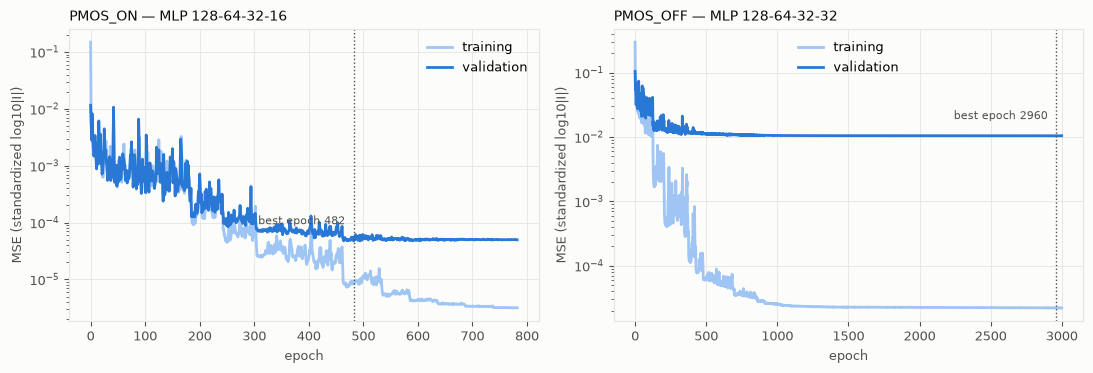

median err %  95th pct err %  mean err %
PMOS_ON  train        0.3264           1.319      0.4555
         val          0.3448           1.618      0.5595
PMOS_OFF train        0.2928           1.202        0.41
         val          0.3296           2.019       1.834

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, case in zip(axes, CASES):
    h = MLP_INFO[case]["history"]
    best_epoch = int(np.argmin(h["val"]))
    ax.plot(h["train"], color=LIGHT_BLUE, lw=2, label="training")
    ax.plot(h["val"], color=BLUE, lw=2, label="validation")
    ax.axvline(best_epoch, color=INK_2, lw=1, ls=":")
    ax.annotate(f"best epoch {best_epoch}", (best_epoch, h["val"][best_epoch]), xytext=(-6, 12),
                textcoords="offset points", ha="right", color=INK_2, fontsize=8)
    ax.set(yscale="log", xlabel="epoch", ylabel="MSE (standardized log10|I|)")
    ax.set_title(f"{case} — MLP {'-'.join(map(str, MLP_INFO[case]['hidden']))}", loc="left")
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# kept model: error on the training data vs on the validation data
pd.DataFrame({(case, part): metrics_table(split[case][f"Y_{part}"],
                                          mlp_predict(MLP_INFO[case]["net"], case, split[case][f"Xs_{part}"]))
                            .loc["average", ["median err %", "95th pct err %", "mean err %"]]
              for case in CASES for part in ("train", "val")}).T

**Reading the result:** the training loss ends far below the validation loss, but the median errors on both sets are
close. So the typical sample is predicted just as well on new data; the gap comes from a **few hard points** that the
network learns by heart on the training set but cannot predict on new data. In PMOS_OFF these are mostly samples where the
two parts of `id` (channel leakage and gate-drain tunnelling) nearly cancel, so |id| dips sharply and its log changes
very fast. Early stopping keeps the epoch with the best validation loss, so the training after it does not harm the
kept model.

## Model 4b — MLP with a physics-informed loss (Kirchhoff's current law)

**Physics:** charge cannot pile up inside the transistor, so the four terminal currents always sum to zero:

$$I_d + I_g + I_s + I_b = 0$$

The SPICE data obeys this to ~1e-6 of the largest current (data-quality check in section 3). The plain MLP predicts the four
currents **independently**, so nothing forces its predictions to obey it. The Kirchhoff loss adds that rule to training:

$$\text{loss} = \underbrace{\text{MSE}(\log_{10}|I|)}_{\text{as before}} \;+\; \lambda \cdot \text{mean}\left[\left(\frac{s_d|\hat I_d| + s_g|\hat I_g| + s_s|\hat I_s| + s_b|\hat I_b|}{|\hat I_d| + |\hat I_g| + |\hat I_s| + |\hat I_b|}\right)^2\right]$$

| Part | Meaning |
|---|---|
| \|Î\| = 10^(predicted log10\|I\|) | the predicted current magnitudes |
| s = ±1 | the **true** signs from the training data (`S_train`); needed only during training |
| dividing by Σ\|Î\| | makes the penalty scale-free (currents span many decades) |
| λ | how strongly the rule is enforced |

**Why it should help:** it ties the four outputs together. In PMOS_OFF, for example, it forces |id| and |is| to be consistent
with `ig` and `ib`, which are predicted very accurately, including near the hard cancellation points. On the original
10,000-sample data, λ = 10 improved the PMOS_OFF mean error from 5.04 % to 4.14 % (3-seed average).

**Setup:** same network as the chosen plain MLP for each case, same optimizer, learning-rate schedule and early stopping
(on the plain validation MSE, so the two MLPs are selected the same way). λ is chosen on the validation set from 10, 30, 100,
using the **mean** error, because the mean is what this step is meant to improve. Prediction works exactly as before.

In [27]:
def train_mlp_kcl(case, hidden, lam, lr, weight_decay, batch_size, max_epochs, patience):
    # same as train_mlp, plus the Kirchhoff penalty in the training loss
    s = split[case]
    torch.manual_seed(SEED)
    as_tensor = lambda a: torch.tensor(a, dtype=torch.float32)
    Xt, Yt, St = as_tensor(s["Xs_train"]), as_tensor(s["Ys_train"]), as_tensor(s["S_train"])
    Xv, Yv = as_tensor(s["Xs_val"]), as_tensor(s["Ys_val"])
    mu, sd = as_tensor(y_scalers[case].mean_), as_tensor(y_scalers[case].scale_)

    net = build_mlp(hidden)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=50, min_lr=1e-6)
    loss_fn = nn.MSELoss()
    gen = torch.Generator().manual_seed(SEED)

    best, best_state, wait = float("inf"), None, 0
    history = {"train": [], "val": []}
    for epoch in range(max_epochs):
        net.train()
        batch_losses = []
        for b in torch.randperm(len(Xt), generator=gen).split(batch_size):
            opt.zero_grad()
            out = net(Xt[b])
            mse = loss_fn(out, Yt[b])
            mag = 10 ** (out * sd + mu - mu.max())                 # predicted |I| (a common factor cancels in the ratio)
            kcl = ((St[b] * mag).sum(1) / mag.sum(1)) ** 2        # (Id + Ig + Is + Ib) / (|Id| + |Ig| + |Is| + |Ib|)
            loss = mse + lam * kcl.mean()
            loss.backward()
            opt.step()
            batch_losses.append(loss.item())
        net.eval()
        with torch.no_grad():
            val_loss = loss_fn(net(Xv), Yv).item()                 # selection on the same validation MSE as the plain MLP
        history["train"].append(np.mean(batch_losses))
        history["val"].append(val_loss)
        sched.step(val_loss)
        if val_loss < best:
            best, best_state, wait = val_loss, copy.deepcopy(net.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(best_state)
    return net, history

def kcl_residual(case, Y_log_pred, part="val"):
    # Kirchhoff residual of predicted currents (true signs): |sum of signed currents| / sum of |currents|
    mag = 10 ** Y_log_pred
    S = split[case][f"S_{part}"]
    return np.abs((S * mag).sum(1)) / mag.sum(1)

### Choosing λ

Each case uses the hidden layers of its chosen plain MLP; λ = 10, 30 and 100 are trained and the one with the lowest
validation **mean** error is kept (takes ~17 minutes in total).

In [28]:
LAMBDAS = [10, 30, 100]

kcl_runs, KCL_INFO = [], {}
for case in CASES:
    hidden = MLP_INFO[case]["hidden"]
    for lam in LAMBDAS:
        t0 = time.time()
        net, history = train_mlp_kcl(case, hidden, lam, **MLP_PARAMS)
        seconds = time.time() - t0
        pred = mlp_predict(net, case, split[case]["Xs_val"])
        a = metrics_table(split[case]["Y_val"], pred).loc["average"]
        kcl_runs.append({"case": case, "lambda": lam, "hidden layers": "-".join(map(str, hidden)),
                         "epochs": len(history["val"]), "mean err %": a["mean err %"],
                         "median err %": a["median err %"], "95th pct err %": a["95th pct err %"], "time s": seconds})
        print(f"{case:9s} lambda {lam:4d}   mean err {a['mean err %']:5.2f} %   median err {a['median err %']:5.2f} %   "
              f"95th pct {a['95th pct err %']:5.2f} %   ({seconds:.0f} s)")
        if case not in KCL_INFO or a["mean err %"] < KCL_INFO[case]["mean"]:
            KCL_INFO[case] = {"mean": a["mean err %"], "lambda": lam, "net": net, "history": history,
                              "pred": pred, "seconds": seconds}

pd.DataFrame(kcl_runs).set_index(["case", "lambda"])

PMOS_ON   lambda   10   mean err  0.76 %   median err  0.43 %   95th pct  2.15 %   (126 s)


PMOS_ON   lambda   30   mean err  1.12 %   median err  0.65 %   95th pct  3.30 %   (133 s)


PMOS_ON   lambda  100   mean err  1.22 %   median err  0.66 %   95th pct  3.69 %   (302 s)


PMOS_OFF  lambda   10   mean err  4.54 %   median err  1.99 %   95th pct  8.29 %   (51 s)


PMOS_OFF  lambda   30   mean err  1.50 %   median err  0.35 %   95th pct  2.25 %   (343 s)


PMOS_OFF  lambda  100   mean err  3.30 %   median err  1.59 %   95th pct  6.95 %   (74 s)


hidden layers  epochs  mean err %  median err %  \
case     lambda                                                   
PMOS_ON  10      128-64-32-16    1250      0.7608        0.4256   
         30      128-64-32-16    1319       1.116        0.6453   
         100     128-64-32-16    3000       1.218        0.6561   
PMOS_OFF 10      128-64-32-32     483       4.544         1.987   
         30      128-64-32-32    3000       1.505         0.346   
         100     128-64-32-32     702       3.302         1.587   

                 95th pct err %  time s  
case     lambda                          
PMOS_ON  10               2.155   126.3  
         30               3.303   132.8  
         100              3.689   302.2  
PMOS_OFF 10               8.292   50.99  
         30               2.254   343.1  
         100               6.95   74.38

In [29]:
# keep the best lambda for each case
for case in CASES:
    b = KCL_INFO[case]
    print(f"{case}: best lambda {b['lambda']}")
    record(case, "MLP+Kirchhoff", b["net"], b["pred"], b["seconds"])

# plain MLP vs MLP + Kirchhoff loss (validation, average over the 4 currents)
rows = []
for case in CASES:
    for name, pred in [("MLP", MLP_INFO[case]["pred"]), ("MLP+Kirchhoff", KCL_INFO[case]["pred"])]:
        a = RESULTS[case][name]["metrics"].loc["average"]
        rows.append({"case": case, "model": name, "mean err %": a["mean err %"], "median err %": a["median err %"],
                     "95th pct err %": a["95th pct err %"],
                     "Kirchhoff residual (median)": np.median(kcl_residual(case, pred))})
display(pd.DataFrame(rows).set_index(["case", "model"]))

# MLP + Kirchhoff — validation scores per current
pd.concat({case: RESULTS[case]["MLP+Kirchhoff"]["metrics"] for case in CASES}, names=["case", "current"])

PMOS_ON: best lambda 10
PMOS_ON   MLP+Kirchhoff validation: mean err   0.76 %   median err   0.43 %   95th pct   2.15 %   (126.3 s)
PMOS_OFF: best lambda 30
PMOS_OFF  MLP+Kirchhoff validation: mean err   1.50 %   median err   0.35 %   95th pct   2.25 %   (343.1 s)


mean err %  median err %  95th pct err %  \
case     model                                                     
PMOS_ON  MLP                0.5595        0.3448           1.618   
         MLP+Kirchhoff      0.7608        0.4256           2.155   
PMOS_OFF MLP                 1.834        0.3296           2.019   
         MLP+Kirchhoff       1.505         0.346           2.254   

                        Kirchhoff residual (median)  
case     model                                       
PMOS_ON  MLP                               0.001329  
         MLP+Kirchhoff                    0.0002618  
PMOS_OFF MLP                               0.001108  
         MLP+Kirchhoff                    0.0001159

R2 (log|I|)  mean err %  median err %  95th pct err %
case     current                                                       
PMOS_ON  id            0.9997      0.7582        0.3586           1.631
         ig            0.9999      0.8593        0.4256           2.757
         is            0.9999      0.5847        0.3591           1.611
         ib                 1      0.8411        0.5591            2.62
         average       0.9999      0.7608        0.4256           2.155
PMOS_OFF id             0.996       2.903        0.4698           2.753
         ig            0.9999      0.6124        0.3045           1.769
         is            0.9986       1.459        0.4683           3.001
         ib            0.9716       1.044        0.1414           1.491
         average       0.9915       1.505         0.346           2.254

**Reading the result:**

| | PMOS_ON | PMOS_OFF |
|---|---|---|
| Best λ | 10 | 30 |
| Mean error: plain MLP → Kirchhoff | 0.56 % → 0.76 % (worse) | **1.83 % → 1.50 %** (better, mostly from `is`: 2.59 % → 1.46 %) |
| Median error | 0.34 % → 0.43 % | 0.33 % → 0.35 % (about the same) |
| 95th percentile | 1.62 % → 2.15 % | 2.02 % → 2.25 % (slightly worse) |
| Kirchhoff residual of the predictions (median) | 1.3e-3 → 2.6e-4 | 1.1e-3 → 1.2e-4 |

- The predictions obey Kirchhoff's law **5–10× better** with the extra term, as intended.
- **PMOS_OFF:** the mean error drops, because the rule ties the hard `id` / `is` values to the accurate `ig` / `ib`.
- **PMOS_ON:** worse for every λ. These currents have no cancellation points and the plain MLP already nearly obeys
  Kirchhoff's law, so the extra term only competes with the accuracy term.
- **Sensitivity:** for PMOS_OFF, λ = 10 and λ = 100 stopped early at much worse errors (4.5 % and 3.3 %). Training with the
  extra term is less stable, and each λ was trained with one seed only.

**Choice (validation mean error):** plain MLP for PMOS_ON, MLP + Kirchhoff loss (λ = 30) for PMOS_OFF. Both are confirmed
on the test set in the final step.

# Final step — save the comparison table and the chosen models

1. **Validation table** of every model and case → `ML_Models/Results/validation_comparison_PMOS.csv`
2. **Chosen model per case:** the lowest validation **mean** error (the project targets mean accuracy)
3. **Saved model files** → `ML_Models/Saved_Models/<case>.pt`, self-contained: weights, hidden layers, feature list and
   both scalers, so `ML_Models/Scripts/leakage_model.py` can load them without this notebook

The **test set is not used here.** The chosen models are evaluated on it once, in `ML_Models/Results/model_evaluation.ipynb`.

In [30]:
RESULTS_DIR, MODEL_DIR = ROOT / "ML_Models" / "Results", ROOT / "ML_Models" / "Saved_Models"
MODEL_TYPE = {"RandomForest": "Random forest", "XGBoost": "XGBoost", "PolyRidge": "Polynomial (Ridge)",
              "MLP": "MLP", "MLP+Kirchhoff": "MLP + Kirchhoff loss"}

# 1. validation table: every model, every case, every current
rows = []
for case in CASES:
    for name, r in RESULTS[case].items():
        for current, m in r["metrics"].iterrows():
            rows.append({"case": case, "model": MODEL_TYPE[name], "current": current, **m.to_dict(), "train time s": r["time_s"]})
comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS_DIR / "validation_comparison_PMOS.csv", index=False)

# 2. chosen model per case: lowest validation mean error (average over the 4 currents)
avg = comparison[comparison["current"] == "average"].set_index(["case", "model"])
chosen = {case: avg.loc[case, "mean err %"].idxmin() for case in CASES}

# 3. save the chosen models
def save_mlp(case, model_name, net, hidden, extra):
    path = MODEL_DIR / f"{case}.pt"
    torch.save({"case": case, "kind": "pmos", "model": model_name, "hidden": list(hidden), "activation": "SiLU",
                "features": ALL_FEATURES, "outputs": OUTPUT_COLS,
                "x_mean": scalers[case].mean_.tolist(), "x_scale": scalers[case].scale_.tolist(),
                "y_mean": y_scalers[case].mean_.tolist(), "y_scale": y_scalers[case].scale_.tolist(),
                "dataset": f"{case}_20k.csv", "seed": SEED, "split": "80/10/10",
                "validation": avg.loc[(case, model_name)][["R2 (log|I|)", "mean err %", "median err %", "95th pct err %"]].to_dict(),
                **extra, "state_dict": net.state_dict()}, path)
    return path

for case, model_name in chosen.items():
    if model_name == "MLP":
        path = save_mlp(case, model_name, MLP_INFO[case]["net"], MLP_INFO[case]["hidden"], {"kirchhoff_lambda": 0.0})
    elif model_name == "MLP + Kirchhoff loss":
        path = save_mlp(case, model_name, KCL_INFO[case]["net"], MLP_INFO[case]["hidden"],
                        {"kirchhoff_lambda": float(KCL_INFO[case]["lambda"])})
    else:
        raise NotImplementedError(f"saving a {model_name} model is not implemented")
    print(f"{case}: chosen {model_name:22s} validation mean err {avg.loc[(case, model_name), 'mean err %']:.2f} %  -> {path.relative_to(ROOT)}")

# validation summary (average over the 4 currents)
avg[["R2 (log|I|)", "mean err %", "median err %", "95th pct err %"]]

PMOS_ON: chosen MLP                    validation mean err 0.56 %  -> ML_Models/Saved_Models/PMOS_ON.pt
PMOS_OFF: chosen MLP + Kirchhoff loss   validation mean err 1.50 %  -> ML_Models/Saved_Models/PMOS_OFF.pt


R2 (log|I|)  mean err %  median err %  \
case     model                                                         
PMOS_ON  Random forest              0.9877       20.32         14.21   
         XGBoost                    0.9989       4.373         2.858   
         Polynomial (Ridge)         0.9968       7.015         4.464   
         MLP                             1      0.5595        0.3448   
         MLP + Kirchhoff loss       0.9999      0.7608        0.4256   
PMOS_OFF Random forest              0.9226       29.17         9.752   
         XGBoost                    0.9851       13.43         3.332   
         Polynomial (Ridge)         0.8683       69.96         14.59   
         MLP                        0.9897       1.834        0.3296   
         MLP + Kirchhoff loss       0.9915       1.505         0.346   

                               95th pct err %  
case     model                                 
PMOS_ON  Random forest                  54.42  
         XGBoost                        12.61  
         Polynomial (Ridge)              22.1  
         MLP                            1.618  
         MLP + Kirchhoff loss           2.155  
PMOS_OFF Random forest                  49.83  
         XGBoost                        19.42  
         Polynomial (Ridge)              77.3  
         MLP                            2.019  
         MLP + Kirchhoff loss           2.254